# Customer Reviews Intelligence System using NLP and Machine Learning
**Course:** AI4001 – Fundamentals of Natural Language Processing  
**Assignment:** 1  
**Dataset:** Amazon Fine Food Reviews (https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews)

## 0. Install & Import Libraries

In [20]:
# Install required libraries (run once)
!pip install pandas numpy scikit-learn nltk vaderSentiment gradio matplotlib seaborn wordcloud --quiet

ERROR: Could not find a version that satisfies the requirement vaderSentiment (from versions: none)
ERROR: No matching distribution found for vaderSentiment


In [21]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import NMF

#from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

print('All libraries imported successfully!')

[nltk_data] Error loading punkt: <urlopen error [Errno -3] Temporary
[nltk_data]     failure in name resolution>
[nltk_data] Error loading stopwords: <urlopen error [Errno -3]
[nltk_data]     Temporary failure in name resolution>
[nltk_data] Error loading wordnet: <urlopen error [Errno -3] Temporary
[nltk_data]     failure in name resolution>


All libraries imported successfully!


[nltk_data] Error loading punkt_tab: <urlopen error [Errno -3]
[nltk_data]     Temporary failure in name resolution>


## 1. Load Dataset

In [22]:
# Load Amazon Fine Food Reviews
# Download from: https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews
# Place Reviews.csv in the same directory as this notebook

try:
    df = pd.read_csv('/kaggle/input/datasets/organizations/snap/amazon-fine-food-reviews/Reviews.csv')
    print('Dataset loaded from file.')
except FileNotFoundError:
    print("Error")

# Use a sample if dataset is large
if len(df) > 50000:
    df = df.sample(50000, random_state=42)

# Keep only relevant columns
if 'Text' in df.columns and 'Score' in df.columns:
    df = df[['Text', 'Score']].dropna()

print(f'Dataset shape: {df.shape}')
df.head()

Dataset loaded from file.
Dataset shape: (50000, 2)


,Text,Score
165256,Having tried a couple of other brands of glute...,5
231465,My cat loves these treats. If ever I can't fin...,5
427827,A little less than I expected. It tends to ha...,3
433954,"First there was Frosted Mini-Wheats, in origin...",2
70260,and I want to congratulate the graphic artist ...,5


## Task 1: Text Preprocessing

In [23]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess(text):
    """Full NLP preprocessing pipeline."""
    # Lowercase
    text = str(text).lower()
    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)
    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)
    # Tokenize
    tokens = word_tokenize(text)
    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

# Show before/after examples
samples = df['Text'].head(5).tolist()
print('=== Before vs After Preprocessing ===\n')
for i, s in enumerate(samples):
    print(f'[{i+1}] BEFORE: {s[:120]}')
    print(f'    AFTER:  {preprocess(s)[:120]}')
    print()

# Apply preprocessing
df['clean_text'] = df['Text'].apply(preprocess)
print('Preprocessing complete!')

=== Before vs After Preprocessing ===

[1] BEFORE: Having tried a couple of other brands of gluten-free sandwich cookies, these are the best of the bunch.  They're crunchy
    AFTER:  tried couple brand gluten free sandwich cooky best bunch crunchy true texture real cooky gluten free might think filling

[2] BEFORE: My cat loves these treats. If ever I can't find her in the house, I just pop the top and she bolts out of wherever she w
    AFTER:  cat love treat ever find house pop top bolt wherever hiding come get treat like crunchy treat much perfect given three f

[3] BEFORE: A little less than I expected.  It tends to have a muddy taste - not what I expected since they said it was the favorite
    AFTER:  little less expected tends muddy taste expected since said favorite company

[4] BEFORE: First there was Frosted Mini-Wheats, in original size, then there was Frosted Mini-Wheats Bite Size. Well, if for some r
    AFTER:  first frosted mini wheat original size frosted mini wheat bi

## Task 2: Feature Extraction – BoW vs TF-IDF

Naive Bayes Accuracy with BoW:   0.9012
Naive Bayes Accuracy with TF-IDF: 0.8818


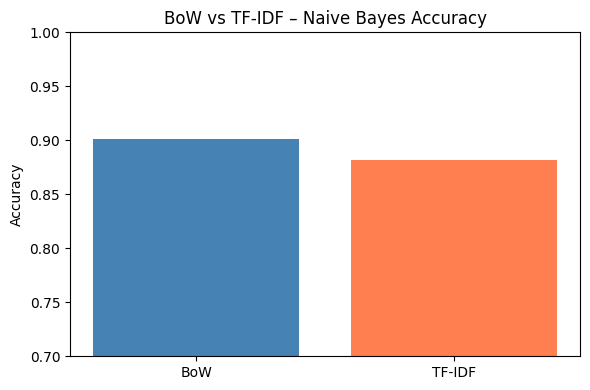

TF-IDF generally performs better as it down-weights common words and highlights discriminative terms.


In [24]:
# Create sentiment labels (binary: positive >= 4, negative <= 2)
df['sentiment'] = df['Score'].apply(lambda x: 'positive' if x >= 4 else ('negative' if x <= 2 else 'neutral'))
df_binary = df[df['sentiment'] != 'neutral'].copy()

X = df_binary['clean_text']
y = df_binary['sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bag of Words
bow_vectorizer = CountVectorizer(max_features=5000)
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

# TF-IDF
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Compare using Naive Bayes
nb_bow = MultinomialNB()
nb_bow.fit(X_train_bow, y_train)
bow_acc = nb_bow.score(X_test_bow, y_test)

nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_tfidf, y_train)
tfidf_acc = nb_tfidf.score(X_test_tfidf, y_test)

print(f'Naive Bayes Accuracy with BoW:   {bow_acc:.4f}')
print(f'Naive Bayes Accuracy with TF-IDF: {tfidf_acc:.4f}')

# Bar chart comparison
plt.figure(figsize=(6,4))
plt.bar(['BoW', 'TF-IDF'], [bow_acc, tfidf_acc], color=['steelblue','coral'])
plt.title('BoW vs TF-IDF – Naive Bayes Accuracy')
plt.ylabel('Accuracy')
plt.ylim(0.7, 1.0)
plt.tight_layout()
plt.savefig('bow_vs_tfidf.png', dpi=100)
plt.show()
print('TF-IDF generally performs better as it down-weights common words and highlights discriminative terms.')

## Task 3: ML Sentiment Analysis (Logistic Regression with TF-IDF)

Logistic Regression – Classification Report:
              precision    recall  f1-score   support

    negative       0.84      0.53      0.65      1345
    positive       0.92      0.98      0.95      7897

    accuracy                           0.92      9242
   macro avg       0.88      0.76      0.80      9242
weighted avg       0.91      0.92      0.91      9242



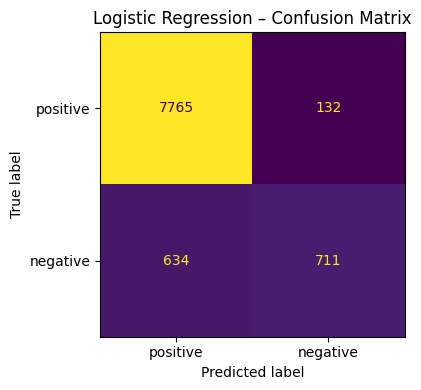

In [25]:
# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
y_pred_lr = lr_model.predict(X_test_tfidf)

print('Logistic Regression – Classification Report:')
print(classification_report(y_test, y_pred_lr))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr, labels=['positive','negative'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['positive','negative'])
fig, ax = plt.subplots(figsize=(5,4))
disp.plot(ax=ax, colorbar=False)
plt.title('Logistic Regression – Confusion Matrix')
plt.tight_layout()
plt.savefig('lr_confusion_matrix.png', dpi=100)
plt.show()

## Task 4: Intent Classification

Intent Distribution:
intent
Complaint         36962
Delivery Issue    10404
General Query      1750
Refund Request      884
Name: count, dtype: int64


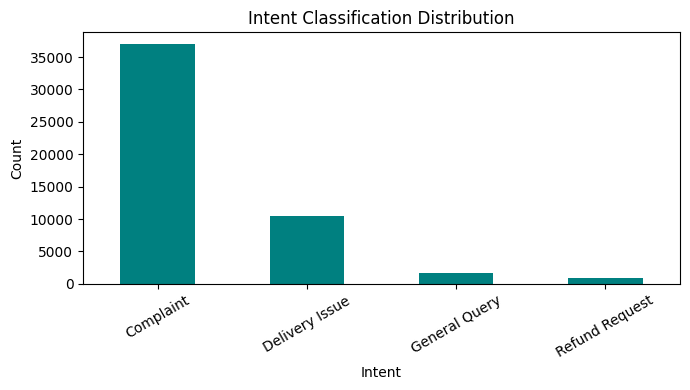


Intent Classifier – Classification Report:
                precision    recall  f1-score   support

     Complaint       0.92      1.00      0.96      7427
Delivery Issue       0.98      0.89      0.93      2058
 General Query       0.25      0.00      0.01       350
Refund Request       0.99      0.47      0.63       165

      accuracy                           0.93     10000
     macro avg       0.78      0.59      0.63     10000
  weighted avg       0.91      0.93      0.91     10000



In [26]:
# Rule-based intent labeling using keywords
def label_intent(text):
    text_lower = str(text).lower()
    refund_kw = ['refund', 'money back', 'return', 'wapas', 'mujhe refund']
    delivery_kw = ['delivery', 'shipping', 'arrived', 'package', 'parcel', 'late', 'deliver', 'dispatch']
    complaint_kw = ['worst', 'terrible', 'horrible', 'damaged', 'broken', 'fake', 'scam', 'bad', 'awful', 'kharab', 'bakwas']
    
    if any(k in text_lower for k in refund_kw):
        return 'Refund Request'
    elif any(k in text_lower for k in delivery_kw):
        return 'Delivery Issue'
    elif any(k in text_lower for k in complaint_kw):
        return 'Complaint'
    elif '?' in text_lower:
        return 'General Query'
    else:
        return 'Complaint'  # default for negative-leaning

df['intent'] = df['Text'].apply(label_intent)

print('Intent Distribution:')
print(df['intent'].value_counts())

plt.figure(figsize=(7,4))
df['intent'].value_counts().plot(kind='bar', color='teal')
plt.title('Intent Classification Distribution')
plt.xlabel('Intent')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('intent_distribution.png', dpi=100)
plt.show()

# ML-based intent classifier
X_intent = df['clean_text']
y_intent = df['intent']

Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_intent, y_intent, test_size=0.2, random_state=42)

tfidf_intent = TfidfVectorizer(max_features=3000)
Xi_train_vec = tfidf_intent.fit_transform(Xi_train)
Xi_test_vec = tfidf_intent.transform(Xi_test)

lr_intent = LogisticRegression(max_iter=1000, random_state=42)
lr_intent.fit(Xi_train_vec, yi_train)
yi_pred = lr_intent.predict(Xi_test_vec)

print('\nIntent Classifier – Classification Report:')
print(classification_report(yi_test, yi_pred))

## Task 5: Topic Modeling with NMF

=== NMF Topics Identified ===

Topic 1 – Product Quality:
  Keywords: taste, product, great, good, like, flavor, one, love, chocolate, amazon

Topic 2 – Taste & Flavor:
  Keywords: coffee, cup, strong, like, flavor, bold, roast, pod, taste, blend

Topic 3 – Delivery & Shipping:
  Keywords: tea, green, drink, bag, taste, flavor, stash, cup, black, iced

Topic 4 – Price & Value:
  Keywords: dog, treat, love, chew, food, training, get, bone, one, small

Topic 5 – Customer Service:
  Keywords: food, cat, eat, dry, chicken, one, canned, brand, like, year

Topic Distribution:
topic_label
Product Quality        30619
Taste & Flavor          6143
Customer Service        4679
Delivery & Shipping     4362
Price & Value           4197
Name: count, dtype: int64


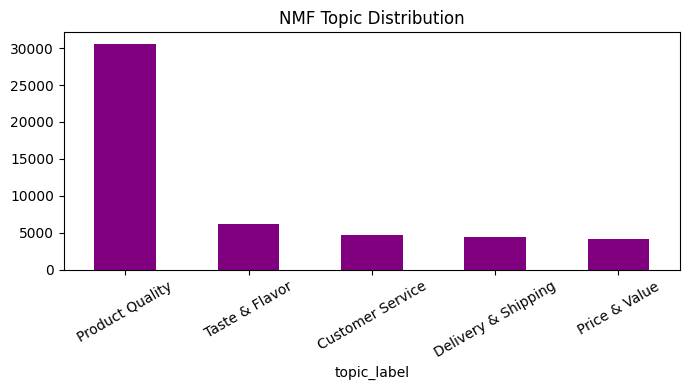

In [27]:
# NMF Topic Modeling
n_topics = 5
tfidf_topic = TfidfVectorizer(max_features=3000, max_df=0.85, min_df=2)
X_topic = tfidf_topic.fit_transform(df['clean_text'])

nmf_model = NMF(n_components=n_topics, random_state=42)
nmf_model.fit(X_topic)

feature_names = tfidf_topic.get_feature_names_out()

topic_labels = ['Product Quality', 'Taste & Flavor', 'Delivery & Shipping', 'Price & Value', 'Customer Service']

print('=== NMF Topics Identified ===')
for i, (topic, label) in enumerate(zip(nmf_model.components_, topic_labels)):
    top_words = [feature_names[j] for j in topic.argsort()[-10:][::-1]]
    print(f'\nTopic {i+1} – {label}:')
    print('  Keywords:', ', '.join(top_words))

# Assign dominant topic to each review
doc_topics = nmf_model.transform(X_topic)
df['dominant_topic'] = doc_topics.argmax(axis=1)
df['topic_label'] = df['dominant_topic'].map(dict(enumerate(topic_labels)))

print('\nTopic Distribution:')
print(df['topic_label'].value_counts())

plt.figure(figsize=(7,4))
df['topic_label'].value_counts().plot(kind='bar', color='purple')
plt.title('NMF Topic Distribution')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('topic_distribution.png', dpi=100)
plt.show()

## Task 6: Model Evaluation – Metrics Discussion

In [28]:
print('=== Model Evaluation Summary ===')
print('\n--- Sentiment Analysis (Logistic Regression) ---')
print(classification_report(y_test, y_pred_lr))

print('\n--- Intent Classification ---')
print(classification_report(yi_test, yi_pred))

print("""
=== Metric Justification ===

For this customer review system, F1-Score is the most appropriate primary metric because:

1. Class Imbalance: Positive reviews vastly outnumber negative ones in Amazon data.
   Accuracy alone would be misleading (a model predicting all positives = high accuracy).

2. Business Impact: Missing a genuine complaint (False Negative) is costly —
   the company fails to address customer issues. False Positives create unnecessary alerts.
   F1 balances Precision and Recall.

3. For Intent: Recall is crucial — especially for 'Refund Request' and 'Complaint',
   as failing to detect these can cause customer churn.

Confusion Matrix provides granular insight into error types per class.
""")

=== Model Evaluation Summary ===

--- Sentiment Analysis (Logistic Regression) ---
              precision    recall  f1-score   support

    negative       0.84      0.53      0.65      1345
    positive       0.92      0.98      0.95      7897

    accuracy                           0.92      9242
   macro avg       0.88      0.76      0.80      9242
weighted avg       0.91      0.92      0.91      9242


--- Intent Classification ---
                precision    recall  f1-score   support

     Complaint       0.92      1.00      0.96      7427
Delivery Issue       0.98      0.89      0.93      2058
 General Query       0.25      0.00      0.01       350
Refund Request       0.99      0.47      0.63       165

      accuracy                           0.93     10000
     macro avg       0.78      0.59      0.63     10000
  weighted avg       0.91      0.93      0.91     10000


=== Metric Justification ===

For this customer review system, F1-Score is the most appropriate primary met

## Gradio interface

In [36]:
# ============================================================
# GRADIO INTERFACE (KAGGLE SAFE VERSION)
# No ngrok
# No manual port binding
# ============================================================

import gradio as gr
import numpy as np

# ==========================
# Prediction Function
# ==========================

def analyze_review(review_text):
    
    if not review_text.strip():
        return "Please enter a review.", "-", "-"
    
    # --- Preprocess ---
    clean = preprocess(review_text)
    vec = tfidf.transform([clean])
    
    # --- Sentiment (Naive Bayes) ---
    sentiment = nb.predict(vec)[0]
    
    # --- Intent ---
    intent = intent_model.predict(vec)[0]
    
    # --- Topic Modeling ---
    topic_scores = nmf.transform(vec)[0]
    top_topic_index = int(np.argmax(topic_scores))
    
    feature_names = tfidf.get_feature_names_out()
    keywords = [
        feature_names[i]
        for i in nmf.components_[top_topic_index].argsort()[-6:][::-1]
    ]
    
    topic_result = f"Topic {top_topic_index+1} | Keywords: {', '.join(keywords)}"
    
    return sentiment, intent, topic_result


# ==========================
# Build Interface
# ==========================

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    
    gr.Markdown("## 🛍 Customer Review Intelligence System")
    gr.Markdown("Predicts **Sentiment**, **Intent**, and **Topic** from customer reviews.")
    
    review_input = gr.Textbox(
        label="Enter Customer Review",
        lines=4,
        placeholder="Type review here..."
    )
    
    analyze_btn = gr.Button("Analyze Review")
    
    with gr.Row():
        sentiment_output = gr.Textbox(label="Predicted Sentiment")
        intent_output = gr.Textbox(label="Predicted Intent")
        topic_output = gr.Textbox(label="Identified Topic & Keywords")
    
    analyze_btn.click(
        fn=analyze_review,
        inputs=review_input,
        outputs=[sentiment_output, intent_output, topic_output]
    )
    
    gr.Examples(
        examples=[
            ["This product is amazing. Highly recommended!"],
            ["I want a refund. The package was damaged."],
            ["Delivery was very late and disappointing."],
            ["Worst taste ever. Completely waste of money."],
            ["Is this gluten free?"]
        ],
        inputs=review_input
    )

# ==========================
# Launch (Kaggle Compatible)
# ==========================

demo.launch(
    share=True,     # REQUIRED for Kaggle
    debug=True
)

* Running on local URL:  http://127.0.0.1:7864

Could not create share link. Missing file: /root/.cache/huggingface/gradio/frpc/frpc_linux_amd64_v0.3. 

Please check your internet connection. This can happen if your antivirus software blocks the download of this file. You can install manually by following these steps: 

1. Download this file: https://cdn-media.huggingface.co/frpc-gradio-0.3/frpc_linux_amd64
2. Rename the downloaded file to: frpc_linux_amd64_v0.3
3. Move the file to this location: /root/.cache/huggingface/gradio/frpc


Keyboard interruption in main thread... closing server.
